## HEZD with graphite absorption and emission
Restart the kernel before running all cells. Install the updated `pn_HEZD.py` alongside `instrument_hezd.py` in `lifesim/instrument`. Set `data_dir` to the Earth-spectrum location. By default `Gra_81` is loaded alongside the installed `pn_HEZD.py`; optionally set `gra_file` below to another path.
Choose the reference dust mass, surface-density slope and outer-to-inner radius ratio at the start of **Simulation variables**. Run all cells after changing them. Each sweep restores the reference observation before the next calculation.

In [81]:
from contextlib import contextmanager
import numpy as np
import lifesim
from pathlib import Path
from lifesim.instrument.pn_HEZD import PhotonNoiseHEZD, resolve_stellar_parameters
from lifesim.instrument.instrument_hezd import Instrument
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from lifesim.util import constants

import astropy.units as u
import pandas as pd

## Simulation variables

Choose between the two Hot dust Models

In [82]:

#Model with alpha set to 0
from lifesim.instrument.pn_HEZD import (
    reference_dust_mass,
    reference_alpha,
    reference_b,
)

#Model with alpha freely choosen
#reference_dust_mass = 3.42e-10  # Earth masses at HEZD level 1
#reference_alpha = 1.0           # Surface density proportional to r**(-alpha)
#reference_b = 13.5

In [83]:
# Plot saving options
save_plots = False
plot_parent_path = Path("/Users/noahminder/Documents/MasterThesis/Plots from Report/Week 7")  # Choose the parent directory
plot_folder_name = "HEZD_plots_norm"
plot_dir = plot_parent_path.expanduser() / plot_folder_name
if save_plots:
    plot_dir.mkdir(parents=True, exist_ok=True)


scenario = 'baseline' # Options: 'baseline', 'pessimistic', 'optimistic'
spectral_resolution = 50 # Resolving power (default 100)
minimum_wavelength = 4 # Minimum wavelength of the spectrometer in micron
maximum_wavelength = 18 # Maximum wavelength of the spectrometer in micron
integration_time = 60*60  # Overall integration time in s

planet_radius = 1  # Planet effective radius in Earth radii
planet_angular_separation = 0.1  # Planet angular separation from host star in arcsec
star_distance = 10  # Distance to the target system in pc
star_temperature, star_radius, star_luminosity = resolve_stellar_parameters()

# Tau Ceti reference properties; keep the existing simulated distance of 10 pc.
exozodi_level = 1  # Exozodi level in zodis 
hezd_level = 1  # Dust mass = hezd_level * reference_dust_mass in Earth masses 

# Array-specific:
diameter = 3
baseline = 10 
bl_min = 5
# 'quantum_eff': 0.,
# 'throughput': 0.,
# 'wl_min': 0.,
# 'wl_max': 0.,
# 'spec_res': 0,
# 'bl_max': 0.,
# 'ratio': 0.,
# 't_slew': 0.,
# 't_efficiency': 0.}

# Other:
image_size = 256
# 'wl_optimal': 0.,
# 'n_plugins': 0,
# 'output_path': None,
# 'output_filename': None

# Model-specific
# 'localzodi': '',
# 'habitable': ''

# Optimization-specific
# 'N_pf': 0.,
# 'snr_target': 0.,
# 'limit': None,
# 'habitable': False,
# 't_search': 0.

# color palette for the plots
c_planet = "#009E73"
c_star = "tab:purple" 
c_local = "#F0E442"
c_exo = "tab:orange"
c_hezd = "#D55E00"
c_all = "#FFFFFF"


# Input file: adjust this directory if needed.
data_dir = Path("/Users/noahminder/Documents/MasterThesis/LIFEsim_notebooks")
earth_spectrum_file = data_dir / "Earth_PRTunits_10pc.txt"


In [84]:
# Create bus
bus = lifesim.Bus()

# Set the baseline scenario
bus.data.options.set_scenario(scenario)

# Set some options manually
bus.data.options.set_manual(spec_res=spectral_resolution)
bus.data.options.set_manual(wl_min=minimum_wavelength)
bus.data.options.set_manual(wl_max=maximum_wavelength)
bus.data.options.set_manual(image_size=image_size)
bus.data.options.set_manual(diameter=diameter)
bus.data.options.set_manual(baseline=baseline)
bus.data.options.set_manual(bl_min=bl_min)

# Create the instrument and add it to the bus
instrument = Instrument(name='inst')
bus.add_module(instrument)

# Create the transmission map and add it to the bus
transm = lifesim.TransmissionMap(name='transm')
bus.add_module(transm)

# Create the noise sources and add them to the bus
exo = lifesim.PhotonNoiseExozodi(name='exo')
bus.add_module(exo)

hezd = PhotonNoiseHEZD(name='hezd')
hezd.gra_file = None
def set_reference_dust():
    hezd.dust_mass = reference_dust_mass
    hezd.alpha = reference_alpha
    hezd.b = reference_b
    hezd.r_in = None   # Use the sublimation radius for the current star
    hezd.r_out = None  # Use reference_b times the inner radius

set_reference_dust()
bus.add_module(hezd)

local = lifesim.PhotonNoiseLocalzodi(name='local')
bus.add_module(local)

star = lifesim.PhotonNoiseStar(name='star')
bus.add_module(star)


# Connect all modules
bus.connect(('inst', 'transm'))
bus.connect(('inst', 'exo'))
bus.connect(('inst', 'hezd'))
bus.connect(('inst', 'local'))
bus.connect(('inst', 'star'))
bus.connect(('star', 'transm'))
bus.connect(('hezd', 'transm'))

instrument.apply_options()

## Earth spectrum definition

In [85]:
from lifesim.util.importer import SpectrumImporter
from spectres import spectres

data=pd.read_csv(earth_spectrum_file, header=None, sep='\s+')

lam_PRT=data[0].values*u.micron
f_PRT=data[1].values*u.erg/u.cm**2/u.s/u.Hz
f_lifesim = f_PRT.to(u.photon / u.m**2 / u.s / u.micron,\
                      equivalencies=u.spectral_density(lam_PRT))

f_lifesim = f_lifesim.to(u.photon / u.s / u.meter**3)
lam_lifesim = lam_PRT.to(u.meter)

flux_planet_spectrum=[lam_lifesim, f_lifesim]

def reference_spectrum():
    return instrument.get_spectrum(
        temp_s=star_temperature, radius_s=star_radius, distance_s=star_distance,
        lat_s=0.78, z=exozodi_level, hezd=hezd_level,
        angsep=planet_angular_separation, flux_planet_spectrum=flux_planet_spectrum,
        safe_mode=True, integration_time=integration_time,
        baseline_to_planet=False, baseline=baseline,
    )

# Record both disks' initial orientations before the sweeps.
reference_orientation = hezd.inc, hezd.PA, exo.inc, exo.PA

@contextmanager
def temporary_sweep():
    try:
        yield
    finally:
        set_reference_dust()
        hezd.inc, hezd.PA, exo.inc, exo.PA = reference_orientation
        # Rebuild the reference observation, including its baseline and transmission map.
        reference_spectrum()

spectrum, flux_planet, noise = reference_spectrum()


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


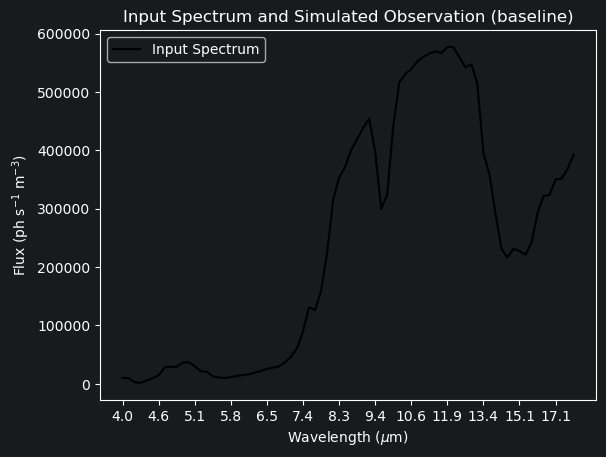

In [86]:
flux_planet_spectrum_rescaled = spectres(new_wavs=instrument.data.inst['wl_bin_edges'],
                                spec_wavs=flux_planet_spectrum[0].value,
                                spec_fluxes=flux_planet_spectrum[1].value,
                                edge_mode=True)

# Compute one draw from noise distribution
random_noise = np.random.normal(0,flux_planet_spectrum_rescaled/spectrum[1],
                                size = flux_planet_spectrum_rescaled.shape)

plt.plot(flux_planet_spectrum_rescaled, color='black', label='Input Spectrum')
#plt.plot(random_noise, color='red', label='Random Noise')

plt.title(f'Input Spectrum and Simulated Observation ({scenario})')
plt.xlabel('Wavelength ($\mu$m)')
plt.xticks(ticks=np.arange(len(flux_planet))[::6], labels=np.round(spectrum[0][::6]*1e6, 1))
plt.ylabel('Flux (ph s$^{-1}$ m$^{-3}$)')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"earth_spectrum_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

In [87]:
# Print the parameters from the single catalog

im_size = instrument.data.options.other['image_size']
print("Image size: ", im_size, " pix")
print("Max pix size: ", np.max([instrument.data.inst['mas_pix']]), " mas / ", np.max([instrument.data.inst['mas_pix']])/1e3 * star_distance, " au")
print("Number of spectral points: ", len(instrument.data.inst['wl_bins']))
print("Nulling baseline: ", instrument.data.inst['bl'], " m")
print("Telescope diameter: ", np.sqrt(instrument.data.inst["telescope_area"]/np.pi), " m")
print("HEZD inner / outer radius [au]:", hezd.r_in_actual, hezd.r_out_actual)
print("HEZD pixel size [mas]:", hezd.mas_pix)


Image size:  256  pix
Max pix size:  4.824616095131381  mas /  0.0482461609513138  au
Number of spectral points:  76
Nulling baseline:  10.0  m
Telescope diameter:  3.0  m
HEZD inner / outer radius [au]: 0.02600199385622296 0.29902292934656405
HEZD pixel size [mas]: 0.23361166355200316


## Hot exozodiacal dust read

In [88]:
def to_Jy(data):  #Convert from ph/s/m3 to Jy
    freq_bin_width = constants.c * (instrument.data.inst['wl_bin_widths'])/(instrument.data.inst['wl_bins']**2)
    ph_to_J = constants.h*constants.c/instrument.data.inst['wl_bins']
    data_Jy = data * ph_to_J * 1e26 * instrument.data.inst['wl_bin_widths']/freq_bin_width
    return data_Jy

def from_Jy(data_Jy):  #Convert from Jy to ph/s/m3
    freq_bin_width = constants.c * (instrument.data.inst['wl_bin_widths'])/(instrument.data.inst['wl_bins']**2)
    ph_to_J = constants.h*constants.c/instrument.data.inst['wl_bins']
    data = data_Jy / ph_to_J / 1e26 / instrument.data.inst['wl_bin_widths'] * freq_bin_width
    return data

4.040404040404041


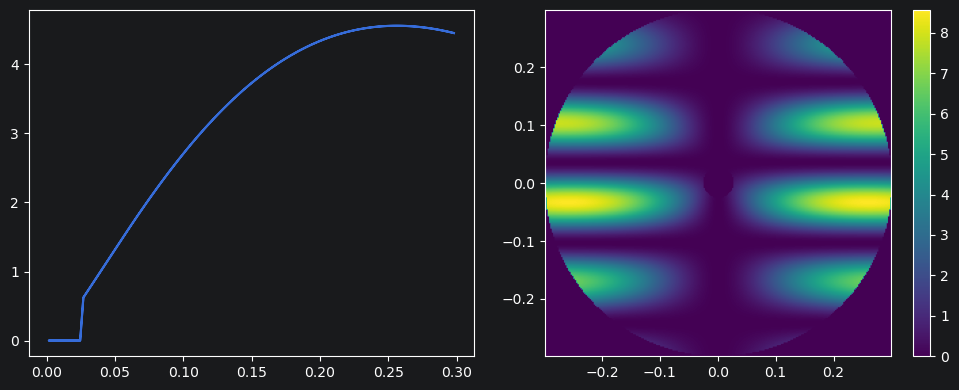

17.963826347680975


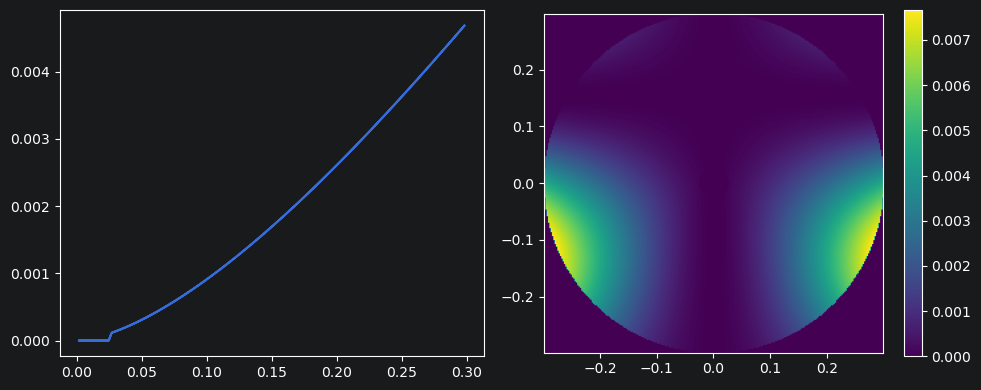

In [89]:
r_au, sigma, temp_map, f_nu, trans_signal, sigma_0 = hezd.signal(None)
im_size = instrument.data.options.other['image_size']
wl_list = instrument.data.inst['wl_bins']

"""
for i in range(len(wl_list)):
    r_au_edge = hezd.r_out_actual

    print(wl_list[i])
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(r_au[i, int(im_size/2)], trans_signal[i, int(im_size/2)])
    imax = np.argmax(sigma[i, int(im_size/2)])
    
    plt.subplot(1, 2, 2)
    plt.imshow(trans_signal[i], 
               extent = (-r_au_edge, r_au_edge, -r_au_edge, r_au_edge))
    plt.tight_layout()
    if save_plots:
        plt.savefig(plot_dir / f"transmission_bin_{i}_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
    plt.show()
"""
i = 0
r_au_edge = hezd.r_out_actual

print(wl_list[i]*1e6)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(r_au[i, int(im_size/2)], trans_signal[i, int(im_size/2)])
imax = np.argmax(sigma[i, int(im_size/2)])

plt.subplot(1, 2, 2)
plt.imshow(trans_signal[i], 
           extent = (-r_au_edge, r_au_edge, -r_au_edge, r_au_edge))
plt.colorbar()
plt.tight_layout()
if save_plots:
    plt.savefig(plot_dir / f"transmission_first_bin_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

i = -1
r_au_edge = hezd.r_out_actual

print(wl_list[i]*1e6)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(r_au[i, int(im_size/2)], trans_signal[i, int(im_size/2)])
imax = np.argmax(sigma[i, int(im_size/2)])

plt.subplot(1, 2, 2)
plt.imshow(trans_signal[i], 
          extent = (-r_au_edge, r_au_edge, -r_au_edge, r_au_edge))
plt.colorbar()
plt.tight_layout()
if save_plots:
    plt.savefig(plot_dir / f"transmission_last_bin_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

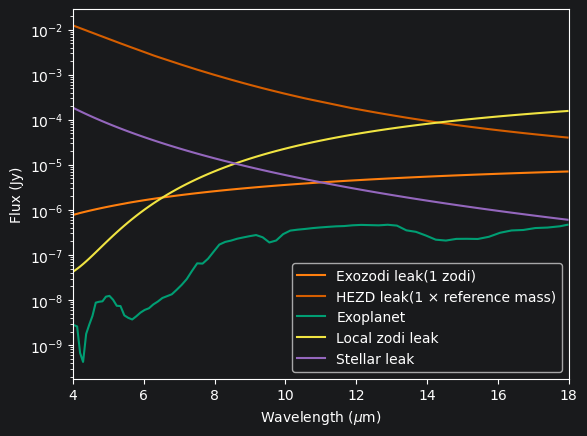

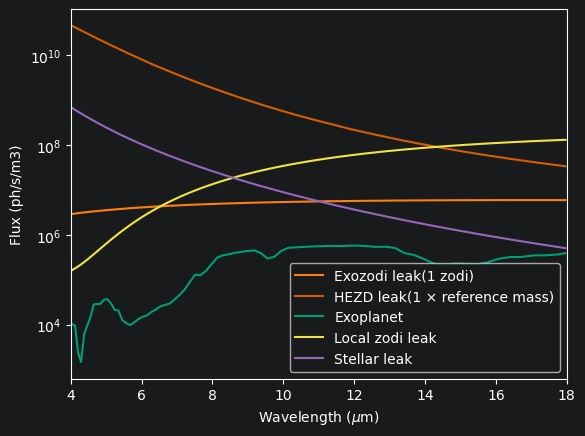

In [90]:
# Comparison of the planet SED and the exozodi and HEZD leakage
instrument.data.single['hezd'] = hezd_level
instrument.data.single['z'] = exozodi_level

factor_m3 = instrument.data.inst['telescope_area'] * instrument.data.inst['wl_bin_widths']

# SED of exozodi leakage
exo_leak = exo.noise(None) / factor_m3
exo_leak_Jy = to_Jy(exo_leak)

# SED of HEZD
f_nu = hezd.signal(None)[3]
HEZD_spectrum = f_nu.sum(axis=(-2, -1)) / factor_m3
HEZD_spectrum_Jy = to_Jy(HEZD_spectrum)

# SED of HEZD leakage
HEZD_leak =  hezd.noise(None) / factor_m3
HEZD_leak_Jy = to_Jy(HEZD_leak)

# SED of local zodi leakage
local_leak =  local.noise(None) / factor_m3
local_leak_Jy = to_Jy(local_leak)

# SED of stellar leakage
star_leak =  star.noise(None) / factor_m3
star_leak_Jy = to_Jy(star_leak)

# SED of Earth twin around tau Ceti
flux_planet_Jy = to_Jy(flux_planet_spectrum_rescaled)

plt.plot(wl_list*1e6, exo_leak_Jy, label="Exozodi leak("+str(exozodi_level)+" zodi)", color=c_exo)
plt.plot(wl_list*1e6, HEZD_leak_Jy, label = "HEZD leak("+str(hezd_level)+" × reference mass)", color=c_hezd)
plt.plot(wl_list*1e6, flux_planet_Jy, color=c_planet, label='Exoplanet')
plt.plot(wl_list*1e6, local_leak_Jy, color=c_local, label='Local zodi leak')
plt.plot(wl_list*1e6, star_leak_Jy, color=c_star, label='Stellar leak')
#plt.plot(wl_list*1e6, HEZD_spectrum_Jy, label="HEZD signal("+str(hezd_level)+" × reference mass)", color="tab:blue")
#plt.hlines(1, minimum_wavelength, maximum_wavelength, ls="--")
#plt.hlines(0.1, minimum_wavelength, maximum_wavelength, ls="--")

plt.xlabel('Wavelength ($\mu$m)')
plt.xlim(minimum_wavelength, maximum_wavelength)
plt.ylabel('Flux (Jy)')
plt.yscale("log")
plt.legend()
if save_plots:
    plt.savefig(plot_dir / f"spectra_jy_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

plt.plot(wl_list*1e6, exo_leak, label="Exozodi leak("+str(exozodi_level)+" zodi)", color=c_exo)
plt.plot(wl_list*1e6, HEZD_leak, label = "HEZD leak("+str(hezd_level)+" × reference mass)", color=c_hezd)
plt.plot(wl_list*1e6, flux_planet_spectrum_rescaled, color=c_planet, label='Exoplanet')
plt.plot(wl_list*1e6, local_leak, color=c_local, label='Local zodi leak')
plt.plot(wl_list*1e6, star_leak, color=c_star, label='Stellar leak')
#plt.plot(wl_list*1e6, HEZD_spectrum, label="HEZD signal("+str(hezd_level)+" × reference mass)", color="tab:blue")

plt.xlabel('Wavelength ($\mu$m)')
plt.xlim(minimum_wavelength, maximum_wavelength)
plt.ylabel('Flux (ph/s/m3)')
plt.yscale("log")
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"spectra_photon_flux_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

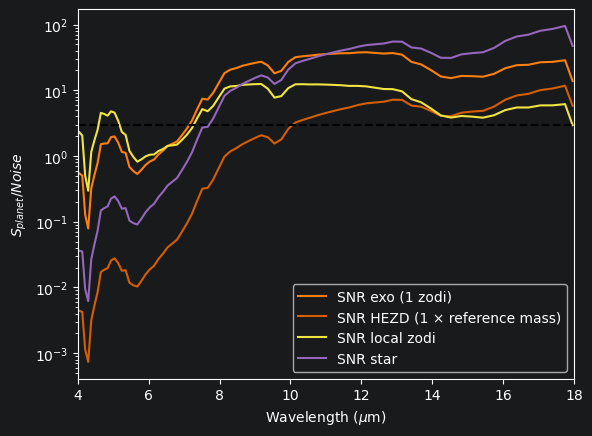

In [91]:
# Plot the SNR of the planet with regards to the noise generated by the exozodi leak
SNR_exo = flux_planet_spectrum_rescaled / np.sqrt(exo_leak) * np.sqrt(factor_m3 * integration_time)

# Plot the SNR of the planet with regards to the noise generated by the HEZD leak
SNR_HEZD = flux_planet_spectrum_rescaled / np.sqrt(HEZD_leak) * np.sqrt(factor_m3 * integration_time)

# Plot the SNR of the planet with regards to the noise generated by the local zodi leak
SNR_local = flux_planet_spectrum_rescaled / np.sqrt(local_leak) * np.sqrt(factor_m3 * integration_time)

# Plot the SNR of the planet with regards to the noise generated by the local zodi leak
SNR_star = flux_planet_spectrum_rescaled / np.sqrt(star_leak) * np.sqrt(factor_m3 * integration_time)

plt.plot(wl_list*1e6, SNR_exo, color=c_exo, label="SNR exo ("+str(exozodi_level)+" zodi)")
plt.plot(wl_list*1e6, SNR_HEZD, color=c_hezd, label="SNR HEZD ("+str(hezd_level)+" × reference mass)")
plt.plot(wl_list*1e6, SNR_local, color=c_local, label="SNR local zodi")
plt.plot(wl_list*1e6, SNR_star, color=c_star, label="SNR star")
plt.xlabel('Wavelength ($\mu$m)')
plt.ylabel("$S_{planet}/Noise$")
plt.hlines(3, minimum_wavelength, maximum_wavelength, ls="--", color="k")
plt.yscale("log")
plt.xlim(minimum_wavelength, maximum_wavelength)
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"planet_snr_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

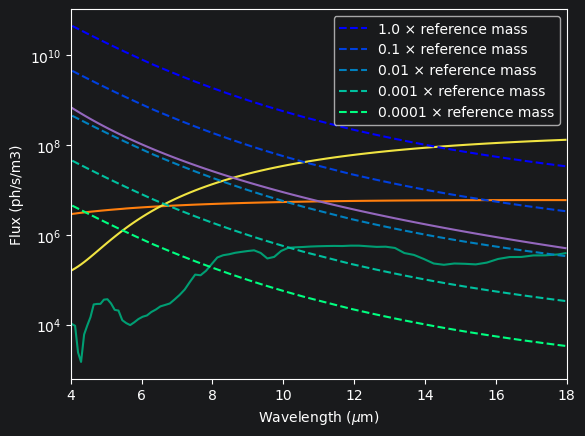

/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [92]:
with temporary_sweep():
    # Plot the Flux for fractions of the reference dust mass
    ceti_level = np.logspace(0, -4, 5)

    colors = plt.cm.winter(np.linspace(0, 1, len(ceti_level)))
    plt.plot(wl_list*1e6, exo_leak, color=c_exo)
    plt.plot(wl_list*1e6, flux_planet_spectrum_rescaled, color=c_planet)
    plt.plot(wl_list*1e6, local_leak, color=c_local)
    plt.plot(wl_list*1e6, star_leak, color=c_star)

    for ceti, c_i in zip(ceti_level, colors):
        instrument.data.single['hezd'] = ceti
        sweep_leak =  hezd.noise(None) / factor_m3
    
        plt.plot(wl_list*1e6, sweep_leak, label = str(ceti)+" × reference mass",  ls="--", color=c_i)

    plt.xlabel('Wavelength ($\mu$m)')
    plt.xlim(minimum_wavelength, maximum_wavelength)
    plt.ylabel('Flux (ph/s/m3)')
    plt.yscale("log")
    plt.legend()

    if save_plots:
        plt.savefig(plot_dir / f"flux_hezd_levels_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
    plt.show()


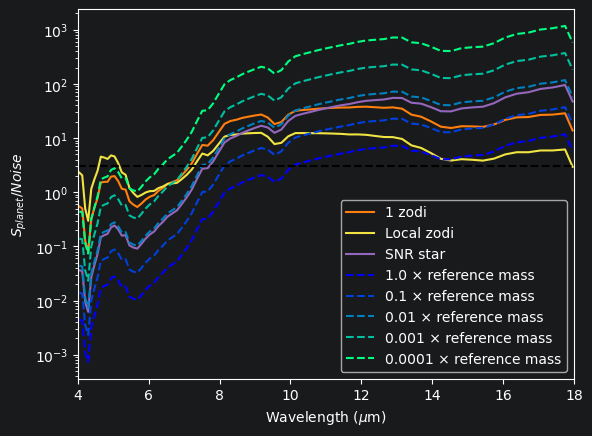

/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [93]:
with temporary_sweep():
    # Plot the same figure for fractions of the reference dust mass 
    ceti_level = np.logspace(0, -4, 5)

    colors = plt.cm.winter(np.linspace(0, 1, len(ceti_level)))
    plt.plot(wl_list*1e6, SNR_exo, color=c_exo, label=str(exozodi_level)+" zodi")
    plt.plot(wl_list*1e6, SNR_local, color=c_local, label="Local zodi")
    plt.plot(wl_list*1e6, SNR_star, color=c_star, label="SNR star")

    for ceti, c_i in zip(ceti_level, colors):
        instrument.data.single['hezd'] = ceti
        trans_i =  hezd.signal(None)[4]

        HEZD_leak_i = trans_i.sum(axis=(-2, -1)) #HEZD leak spectrum in ph/s
        HEZD_leak_i *= 1 / factor_m3

        SNR_i = flux_planet_spectrum_rescaled / np.sqrt(HEZD_leak_i) * np.sqrt(factor_m3 * integration_time)
    
        plt.plot(wl_list*1e6, SNR_i, label=str(ceti)+" × reference mass", ls="--", color=c_i)

    plt.ylabel("$S_{planet}/Noise$")
    plt.xlabel('Wavelength ($\mu$m)')
    plt.hlines(3, minimum_wavelength, maximum_wavelength, ls="--", color="k")
    plt.yscale("log")
    plt.xlim(minimum_wavelength, maximum_wavelength)
    plt.legend()

    if save_plots:
        plt.savefig(plot_dir / f"snr_hezd_levels_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
    plt.show()


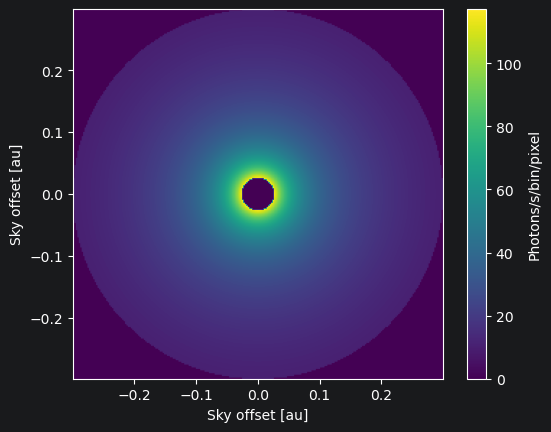

In [94]:
# Inspect the current reference ring without changing later simulations.
r_au, sigma, temp_map, f_nu_disk, trans_signal, sigma_0 = hezd.signal(None)
edge = hezd.r_out_actual
plt.figure()
plt.imshow(f_nu_disk[0], origin='lower', extent=(-edge, edge, -edge, edge))
plt.xlabel('Sky offset [au]')
plt.ylabel('Sky offset [au]')
plt.colorbar(label='Photons/s/bin/pixel')
if save_plots:
    plt.savefig(plot_dir / f"reference_ring_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()


## Impact of HEZD on exoplanet detection

### Impact from hezd level

In [95]:
with temporary_sweep():
    ceti_level = np.logspace(0, -4, 6)

    # Reference SNR without HEZD
    snr_ref = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = 0, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])
    snr_ref_all = np.sqrt(np.sum(snr_ref**2))

    # SNR including HEZD noise
    snr = np.zeros((len(ceti_level), len(instrument.data.inst['wl_bins'])))
    for i in range(len(ceti_level)):
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = ceti_level[i], # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])

    snr_all = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [96]:
# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[:, n_wav]
extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[:, n_wav]
extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[:, n_wav]
extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

In [97]:
with temporary_sweep():
    # For the new nulling baseline of 25m

    # Reference SNR without HEZD
    snr_ref_2 = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = 0, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = 25,
                                 )[0][1])
    snr_ref_all_2 = np.sqrt(np.sum(snr_ref_2**2))

    # SNR including HEZD noise
    snr_2 = np.zeros((len(ceti_level), len(instrument.data.inst['wl_bins'])))
    for i in range(len(ceti_level)):
        snr_2[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = ceti_level[i], # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = 25,
                                     )[0][1])

    snr_all_2 = np.sqrt(np.sum(snr_2**2, axis = 1))
    extra_t_2 = integration_time * (snr_ref_all_2**2 - snr_all_2**2)/(snr_all_2**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [98]:
# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4_2 = snr_ref_2[n_wav]
snr_4_2 = snr_2[:, n_wav]
extra_t_4_2 = integration_time * (snr_ref_4_2**2 - snr_4_2**2)/(snr_4_2**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10_2 = snr_ref_2[n_wav]
snr_10_2 = snr_2[:, n_wav]
extra_t_10_2 = integration_time * (snr_ref_10_2**2 - snr_10_2**2)/(snr_10_2**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18_2 = snr_ref_2[n_wav]
snr_18_2 = snr_2[:, n_wav]
extra_t_18_2 = integration_time * (snr_ref_18_2**2 - snr_18_2**2)/(snr_18_2**2)

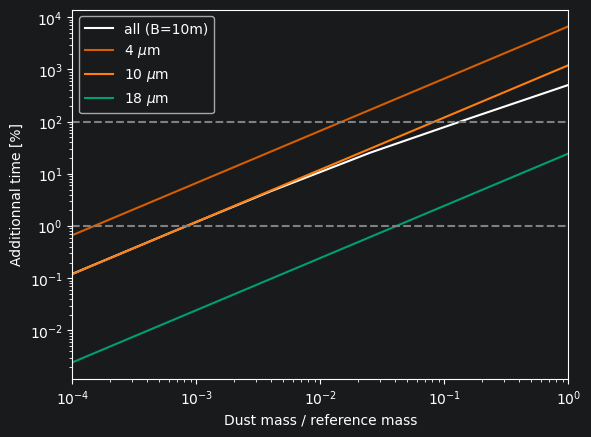

In [99]:
plt.figure()
plt.plot(ceti_level, (extra_t/integration_time)*100, color=c_all, label="all (B=10m)")
plt.plot(ceti_level, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(ceti_level, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(ceti_level, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")
'''
plt.plot(ceti_level, (extra_t_2/integration_time)*100, color="k", ls="dotted", label="all (B=25m)")
plt.plot(ceti_level, (extra_t_4_2/integration_time)*100, color=c_hezd, ls="dotted")
plt.plot(ceti_level, (extra_t_10_2/integration_time)*100, color=c_exo, ls="dotted")
plt.plot(ceti_level, (extra_t_18_2/integration_time)*100, color=c_planet, ls="dotted")
'''
plt.hlines(100, np.min(ceti_level), np.max(ceti_level), ls='--', color='gray')
plt.hlines(1, np.min(ceti_level), np.max(ceti_level), ls='--', color='gray')
plt.xlim(np.min(ceti_level), np.max(ceti_level))
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Dust mass / reference mass')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_hezd_levels_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

### Impact from hezd outer and inner radii, and slope (for constant disk mass)

Radius sweeps use ±50% of the calculated reference radii at fixed total mass. Inner radii below the sublimation radius are sensitivity tests: their grains exceed 2000 K. Automatic radii are restored after each sweep.


In [100]:
with temporary_sweep():
    # Reference SNR without HEZD
    snr_ref = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = 0, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])
    snr_ref = np.array(snr_ref)
    snr_ref_all = np.sqrt(np.sum(snr_ref**2))
    # Reference radii for the current star and chosen dust model.
    hezd.r_in = None
    hezd.r_out = None
    instrument.data.single['hezd'] = hezd_level
    hezd.signal(None)
    r_in_ref = hezd.r_in_actual
    r_out_ref = hezd.r_out_actual


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [101]:
with temporary_sweep():
    # Test with errors on the outer radii
    n_rin = 1
    r_in_list = np.full(n_rin, r_in_ref)
    n_rout = 10
    r_out_list = np.linspace(0.5, 1.5, n_rout) * r_out_ref


    snr = np.zeros((n_rin,n_rout, len(instrument.data.inst['wl_bins'])))
    for i in range(len(r_in_list)):
        for j in range(len(r_out_list)):
            r_in_i = r_in_list[i]
            r_out_i = r_out_list[j]
            if r_out_i <= r_in_i:
                snr[i,j] = np.inf
            else:
                hezd.r_in = r_in_i
                hezd.r_out = r_out_i

                snr[i,j,:] = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = hezd_level, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])

    snr_all = np.sqrt(np.sum(snr**2, axis=2))


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


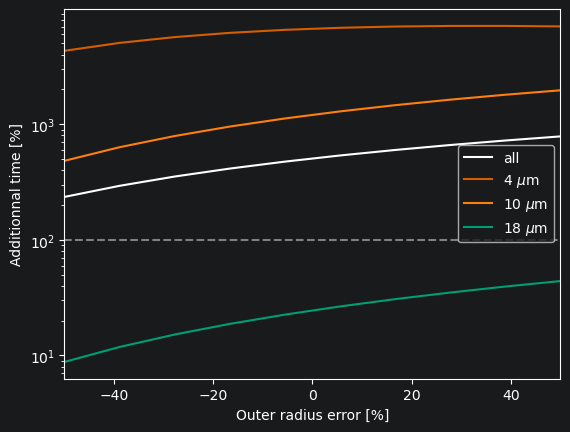

In [102]:
extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)
extra_t_all = (extra_t[0]/integration_time)*100

# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[0, :, n_wav]
extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[0, :, n_wav]
extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[0, :, n_wav]
extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

err_r_out_list = (r_out_list - r_out_ref)/r_out_ref *100

plt.figure()
plt.plot(err_r_out_list, extra_t_all, color=c_all, label="all")
plt.plot(err_r_out_list, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(err_r_out_list, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(err_r_out_list, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")
plt.hlines(100, -50, 50, ls='--', color='gray')
plt.xlim(np.min(err_r_out_list), np.max(err_r_out_list))
#plt.ylim(np.min((extra_t_18/integration_time)*100), np.max((extra_t_4/integration_time)*100))
plt.xscale('linear')
plt.yscale('log')
plt.xlabel('Outer radius error [%]')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_outer_radius_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

In [103]:
with temporary_sweep():
    # Test with errors on the inner radii

    n_rin = 20
    r_in_list = np.linspace(0.5, 1.5, n_rin) * r_in_ref
    n_rout = 1
    r_out_list = np.full(n_rout, r_out_ref)


    snr = np.zeros((n_rin, n_rout, len(instrument.data.inst['wl_bins'])))
    for i in range(len(r_in_list)):
        for j in range(len(r_out_list)):
            r_in_i = r_in_list[i]
            r_out_i = r_out_list[j]
            if r_out_i <= r_in_i:
                snr[i,j] = np.inf
            else:
                hezd.r_in = r_in_i
                hezd.r_out = r_out_i

                snr[i,j,:] = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = hezd_level, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


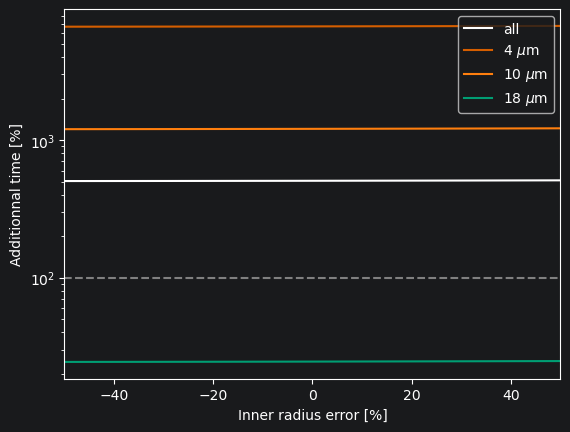

In [104]:
snr_all = np.sqrt(np.sum(snr**2, axis=2))
extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)
extra_t_all = (extra_t[:,0]/integration_time)*100

# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[:, 0, n_wav]
extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[:, 0, n_wav]
extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[:, 0, n_wav]
extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

err_r_in_list = (r_in_list - r_in_ref)/r_in_ref *100

plt.figure()
plt.plot(err_r_in_list, extra_t_all, color=c_all, label="all")
plt.plot(err_r_in_list, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(err_r_in_list, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(err_r_in_list, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")
plt.hlines(100, -50, 50, ls='--', color='gray')
plt.xlim(np.min(err_r_in_list), np.max(err_r_in_list))
#plt.ylim(np.min((extra_t_all/integration_time)*100), np.max((extra_t_10/integration_time)*100))
plt.xscale('linear')
plt.yscale('log')
plt.xlabel('Inner radius error [%]')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_inner_radius_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

In [105]:
with temporary_sweep():
    # Test with slope

    n_alpha = 10
    alpha_list = np.linspace(-5, 5, n_alpha)
    hezd.r_in = None
    hezd.r_out = None

    snr = np.zeros((n_alpha, len(instrument.data.inst['wl_bins'])))
    for i in range(len(alpha_list)):
        hezd.alpha = alpha_list[i]
        snr[i,:] = np.array(instrument.get_spectrum(
                           temp_s=star_temperature,  # star temperature in K
                           radius_s=star_radius,  # star radius in solar radii
                           distance_s=star_distance,  # distance to system in pc
                           lat_s=0.78,  # ecliptic latitude of observation in rad
                           z=exozodi_level,  # zodi level
                           hezd = hezd_level, # hezd level
                           angsep=planet_angular_separation,  # angular separation of planet in arcsec
                           flux_planet_spectrum=flux_planet_spectrum,
                           safe_mode=True,
                           integration_time=integration_time,
                           baseline_to_planet = False,
                           baseline = baseline,
                         )[0][1])


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


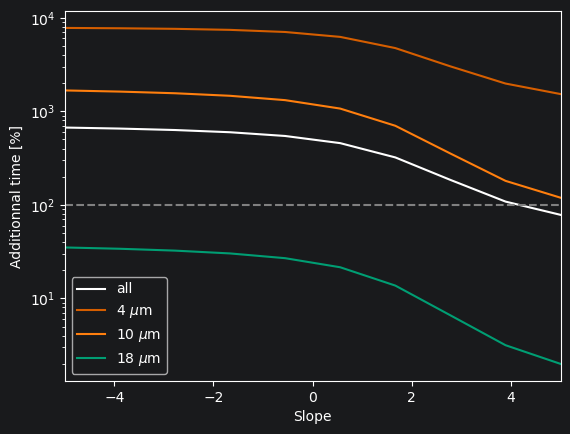

In [106]:
snr_all = np.sqrt(np.sum(snr**2, axis=1))
extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)
extra_t_all = (extra_t/integration_time)*100

# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[:, n_wav]
extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[:, n_wav]
extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[:, n_wav]
extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

plt.figure()
plt.plot(alpha_list, extra_t_all, color=c_all, label="all")
plt.plot(alpha_list, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(alpha_list, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(alpha_list, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")
plt.hlines(100, -50, 50, ls='--', color='gray')
plt.xlim(np.min(alpha_list), np.max(alpha_list))
#plt.ylim(np.min((extra_t_18/integration_time)*100), np.max((extra_t_4/integration_time)*100))
plt.xscale('linear')
plt.yscale('log')
plt.xlabel('Slope')
plt.ylabel('Additionnal time [%]')
plt.legend()

#if save_plots:
 #   plt.savefig(plot_dir / f"time_slope_alpha_{alpha_list.min():g}_to_{alpha_list.max():g}.png", dpi=300, bbox_inches="tight")
plt.show()

### Impact from hezd and exozodi orientation and PA (for constant disk mass)

In [107]:
with temporary_sweep():
    inc = 15
    PA = np.linspace(0, 90, 20)

    hezd.inc = inc
    exo.inc = inc

    # Reference SNR without HEZD
    snr_ref = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = 0, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])
    snr_ref_all_1 = np.sqrt(np.sum(snr_ref**2))

    # SNR including HEZD noise
    snr = np.zeros((len(PA), len(instrument.data.inst['wl_bins'])))
    for i in range(len(PA)):
        hezd.PA = PA[i]
        exo.PA = PA[i]
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = hezd_level, # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])

    snr_all_1 = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t_1 = integration_time * (snr_ref_all_1**2 - snr_all_1**2)/(snr_all_1**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [108]:
# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[:, n_wav]
extra_t_1_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[:, n_wav]
extra_t_1_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[:, n_wav]
extra_t_1_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

In [109]:
with temporary_sweep():
    inc = 45

    hezd.inc = inc
    exo.inc = inc

    # Reference SNR without HEZD
    snr_ref = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = 0, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])
    snr_ref_all_2 = np.sqrt(np.sum(snr_ref**2))

    # SNR including HEZD noise
    snr = np.zeros((len(PA), len(instrument.data.inst['wl_bins'])))
    for i in range(len(PA)):
        hezd.PA = PA[i]
        exo.PA = PA[i]
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = hezd_level, # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])

    snr_all_2 = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t_2 = integration_time * (snr_ref_all_2**2 - snr_all_2**2)/(snr_all_2**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [110]:
# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[:, n_wav]
extra_t_2_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[:, n_wav]
extra_t_2_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[:, n_wav]
extra_t_2_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

In [111]:
with temporary_sweep():
    inc = 80

    hezd.inc = inc
    exo.inc = inc

    # Reference SNR without HEZD
    snr_ref = np.array(instrument.get_spectrum(
                                   temp_s=star_temperature,  # star temperature in K
                                   radius_s=star_radius,  # star radius in solar radii
                                   distance_s=star_distance,  # distance to system in pc
                                   lat_s=0.78,  # ecliptic latitude of observation in rad
                                   z=exozodi_level,  # zodi level
                                   hezd = 0, # hezd level
                                   angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                   flux_planet_spectrum=flux_planet_spectrum,
                                   safe_mode=True,
                                   integration_time=integration_time,
                                   baseline_to_planet = False,
                                   baseline = baseline,
                                 )[0][1])
    snr_ref_all_3 = np.sqrt(np.sum(snr_ref**2))

    # SNR including HEZD noise
    snr = np.zeros((len(PA), len(instrument.data.inst['wl_bins'])))
    for i in range(len(PA)):
        hezd.PA = PA[i]
        exo.PA = PA[i]
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = hezd_level, # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])

    snr_all_3 = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t_3 = integration_time * (snr_ref_all_3**2 - snr_all_3**2)/(snr_all_3**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


In [112]:
# For 4um
wave = 4e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_4 = snr_ref[n_wav]
snr_4 = snr[:, n_wav]
extra_t_3_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

# For 10um
wave = 10e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_10 = snr_ref[n_wav]
snr_10 = snr[:, n_wav]
extra_t_3_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

# For 18um
wave = 18e-6
n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
snr_ref_18 = snr_ref[n_wav]
snr_18 = snr[:, n_wav]
extra_t_3_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)

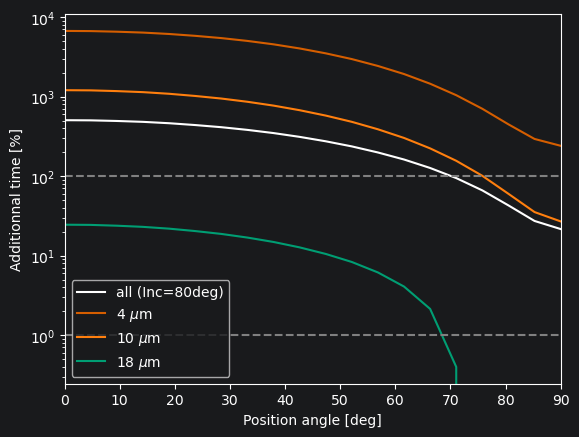

In [113]:
plt.figure()

#plt.plot(PA, (extra_t_1/integration_time)*100, color=c_all, label="Inc=15deg", ls="-")
#plt.plot(PA, (extra_t_2/integration_time)*100, color=c_all, label="Inc=45deg", ls="--")
plt.plot(PA, (extra_t_3/integration_time)*100, color=c_all, label="all (Inc=80deg)", ls="-")

#plt.plot(PA, (extra_t_1_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m", ls="-")
#plt.plot(PA, (extra_t_1_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m", ls="-")
#plt.plot(PA, (extra_t_1_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m", ls="-")

#plt.plot(PA, (extra_t_2_4/integration_time)*100, color=c_hezd, ls="--")
#plt.plot(PA, (extra_t_2_10/integration_time)*100, color=c_exo, ls="--")
#plt.plot(PA, (extra_t_2_18/integration_time)*100, color=c_planet, ls="--")

plt.plot(PA, (extra_t_3_4/integration_time)*100, color=c_hezd, ls="-", label = "4 $\\mu$m")
plt.plot(PA, (extra_t_3_10/integration_time)*100, color=c_exo, ls="-", label = "10 $\\mu$m")
plt.plot(PA, (extra_t_3_18/integration_time)*100, color=c_planet, ls="-", label = "18 $\\mu$m")

plt.hlines(100, np.min(PA), np.max(PA), ls='--', color='gray')
plt.hlines(1, np.min(PA), np.max(PA), ls='--', color='gray')
plt.xlim(np.min(PA), np.max(PA))
plt.xscale('linear')
plt.yscale('log')
plt.xlabel('Position angle [deg]')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_orientation_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()


### Impact of baseline

In [114]:
with temporary_sweep():
    baseline_list = np.linspace(5, 30, 26)

    # Reference SNR without HEZD
    snr_ref = np.zeros((len(baseline_list), len(instrument.data.inst['wl_bins'])))
    for i in range(len(baseline_list)):
        snr_ref[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = 0, # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline_list[i],
                                     )[0][1])
    #For all wavelength
    snr_ref_all = np.sqrt(np.sum(snr_ref**2, axis = 1))


    # SNR with different baseline
    snr = np.zeros((len(baseline_list), len(instrument.data.inst['wl_bins'])))
    for i in range(len(baseline_list)):
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = hezd_level, # hezd level
                                       angsep=planet_angular_separation,  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline_list[i],
                                     )[0][1])

    #For all wavelength
    snr_all = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)

    # For 4um
    wave = 4e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_4 = snr_ref[:, n_wav]
    snr_4 = snr[:, n_wav]
    extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

    # For 10um
    wave = 10e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_10 = snr_ref[:, n_wav]
    snr_10 = snr[:, n_wav]
    extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

    # For 18um
    wave = 18e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_18 = snr_ref[:, n_wav]
    snr_18 = snr[:, n_wav]
    extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


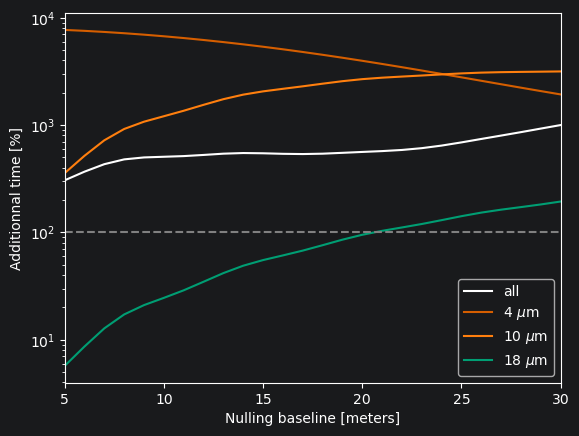

In [115]:
plt.figure()
plt.plot(baseline_list, (extra_t/integration_time)*100, color=c_all, label="all")
plt.plot(baseline_list, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(baseline_list, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(baseline_list, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")

plt.hlines(100, np.min(baseline_list), np.max(baseline_list), ls='--', color='gray')
#plt.hlines(1, np.min(baseline_list), np.max(baseline_list), ls='--', color='gray')
plt.xlim(np.min(baseline_list), np.max(baseline_list))
#plt.xscale('log')
plt.yscale('log')
plt.xlabel('Nulling baseline [meters]')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_baseline_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

### Impact of distance

In [116]:
with temporary_sweep():
    distance_list = np.linspace(5, 50, 25)
    planet_separation_list = 1/distance_list

    # Reference SNR without HEZD
    snr_ref = np.zeros((len(distance_list), len(instrument.data.inst['wl_bins'])))
    for i in range(len(distance_list)):
        snr_ref[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=distance_list[i],  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = 0, # hezd level
                                       angsep=planet_separation_list[i],  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])
    #For all wavelength
    snr_ref_all = np.sqrt(np.sum(snr_ref**2, axis = 1))

    # SNR with different baseline
    snr = np.zeros((len(distance_list), len(instrument.data.inst['wl_bins'])))
    for i in range(len(distance_list)):
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=star_temperature,  # star temperature in K
                                       radius_s=star_radius,  # star radius in solar radii
                                       distance_s=distance_list[i],  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = hezd_level, # hezd level
                                       angsep=planet_separation_list[i],  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])

    #For all wavelength
    snr_all = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)

    # For 4um
    wave = 4e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_4 = snr_ref[:, n_wav]
    snr_4 = snr[:, n_wav]
    extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

    # For 10um
    wave = 10e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_10 = snr_ref[:, n_wav]
    snr_10 = snr[:, n_wav]
    extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

    # For 18um
    wave = 18e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_18 = snr_ref[:, n_wav]
    snr_18 = snr[:, n_wav]
    extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


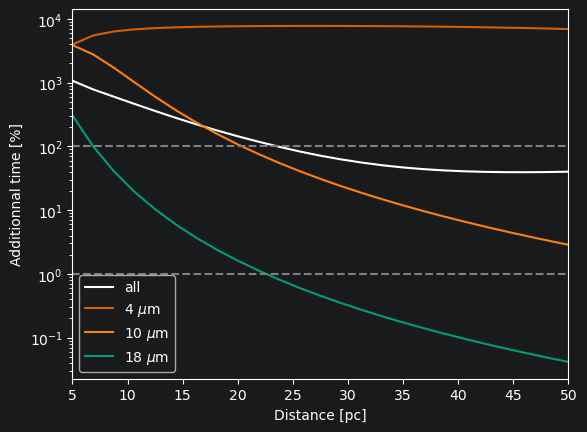

In [117]:
plt.figure()
plt.plot(distance_list, (extra_t/integration_time)*100, color=c_all, label="all")
plt.plot(distance_list, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(distance_list, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(distance_list, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")

plt.hlines(100, np.min(distance_list), np.max(distance_list), ls='--', color='gray')
plt.hlines(1, np.min(distance_list), np.max(distance_list), ls='--', color='gray')
plt.xlim(np.min(distance_list), np.max(distance_list))
#plt.xscale('log')
plt.yscale('log')
plt.xlabel('Distance [pc]')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_distance_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()

### Impact of stellar temperatures

In [118]:
with temporary_sweep():
    hezd.r_in = None   # Use this star's sublimation radius
    hezd.r_out = None  # Use hezd.b times that radius
    temp_list = np.linspace(3900, 7300, 25)
    radius_list = np.linspace(0.7, 1.8, 25)
    planet_separation_list = planet_angular_separation * (temp_list/star_temperature)**2

    # Reference SNR without HEZD
    snr_ref = np.zeros((len(temp_list), len(instrument.data.inst['wl_bins'])))
    for i in range(len(temp_list)):
        snr_ref[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=temp_list[i],  # star temperature in K
                                       radius_s=radius_list[i],  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = 0, # hezd level
                                       angsep=planet_separation_list[i],  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])
    #For all wavelength
    snr_ref_all = np.sqrt(np.sum(snr_ref**2, axis = 1))

    # SNR with different baseline
    snr = np.zeros((len(temp_list), len(instrument.data.inst['wl_bins'])))
    for i in range(len(temp_list)):
        snr[i,:] = np.array(instrument.get_spectrum(
                                       temp_s=temp_list[i],  # star temperature in K
                                       radius_s=radius_list[i],  # star radius in solar radii
                                       distance_s=star_distance,  # distance to system in pc
                                       lat_s=0.78,  # ecliptic latitude of observation in rad
                                       z=exozodi_level,  # zodi level
                                       hezd = hezd_level, # hezd level
                                       angsep=planet_separation_list[i],  # angular separation of planet in arcsec
                                       flux_planet_spectrum=flux_planet_spectrum,
                                       safe_mode=False,
                                       integration_time=integration_time,
                                       baseline_to_planet = False,
                                       baseline = baseline,
                                     )[0][1])

    #For all wavelength
    snr_all = np.sqrt(np.sum(snr**2, axis = 1))
    extra_t = integration_time * (snr_ref_all**2 - snr_all**2)/(snr_all**2)

    # For 4um
    wave = 4e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_4 = snr_ref[:, n_wav]
    snr_4 = snr[:, n_wav]
    extra_t_4 = integration_time * (snr_ref_4**2 - snr_4**2)/(snr_4**2)

    # For 10um
    wave = 10e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_10 = snr_ref[:, n_wav]
    snr_10 = snr[:, n_wav]
    extra_t_10 = integration_time * (snr_ref_10**2 - snr_10**2)/(snr_10**2)

    # For 18um
    wave = 18e-6
    n_wav = np.argmin(np.abs(instrument.data.inst['wl_bins'] - wave))
    snr_ref_18 = snr_ref[:, n_wav]
    snr_18 = snr[:, n_wav]
    extra_t_18 = integration_time * (snr_ref_18**2 - snr_18**2)/(snr_18**2)


/Users/noahminder/Documents/LIFEsim/lifesim/instrument/instrument_hezd.py:465: UserWarning: The get_spectrum function was implemented with a major bug between versions 0.2.16 and 0.2.24 in which the noise level was twice as large as the correct value. If you created results with the versions in question, please validate them with the latest version of LIFEsim.
  warn('The get_spectrum function was implemented with a major bug between versions 0.2.16 '


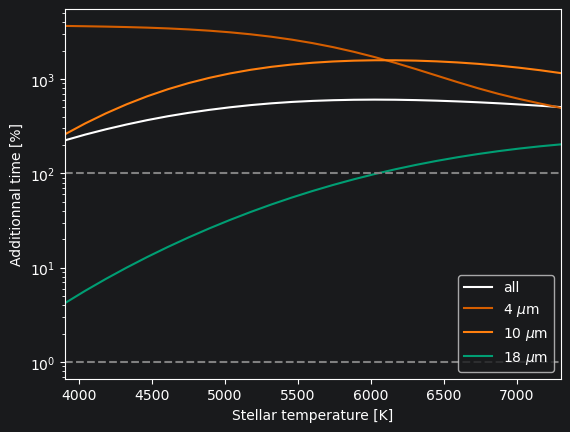

In [119]:
plt.figure()
plt.plot(temp_list, (extra_t/integration_time)*100, color=c_all, label="all")
plt.plot(temp_list, (extra_t_4/integration_time)*100, color=c_hezd, label = "4 $\\mu$m")
plt.plot(temp_list, (extra_t_10/integration_time)*100, color=c_exo, label = "10 $\\mu$m")
plt.plot(temp_list, (extra_t_18/integration_time)*100, color=c_planet, label = "18 $\\mu$m")

plt.hlines(100, np.min(temp_list), np.max(temp_list), ls='--', color='gray')
plt.hlines(1, np.min(temp_list), np.max(temp_list), ls='--', color='gray')
plt.xlim(np.min(temp_list), np.max(temp_list))
#plt.xscale('log')
plt.yscale('log')
plt.xlabel('Stellar temperature [K]')
plt.ylabel('Additionnal time [%]')
plt.legend()

if save_plots:
    plt.savefig(plot_dir / f"time_stellar_temperature_alpha_{hezd.alpha:g}.png", dpi=300, bbox_inches="tight")
plt.show()